PERFORMANCE EVALUATION OF CLASSIFICATION MODELS
Application: Wine Classification
Dataset records: 178
Number of input features: 13
Number of classes: 3
Class names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]

First five records:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81 

C:\Users\Admin\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


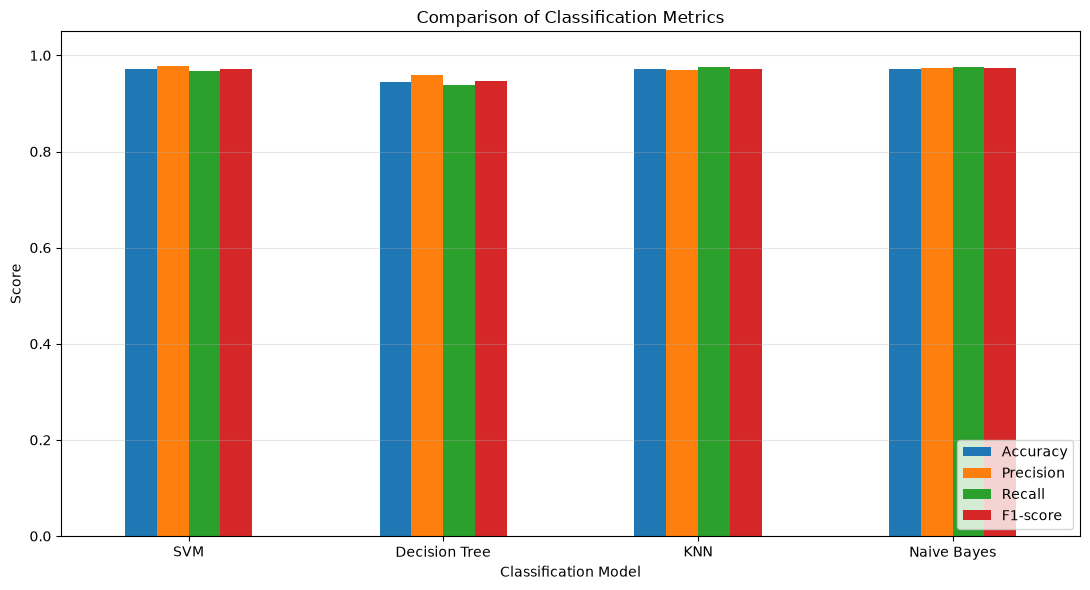

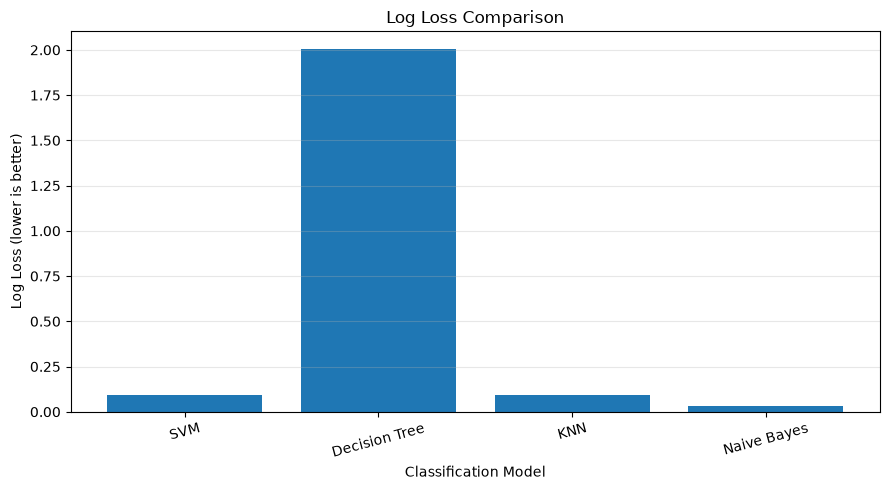

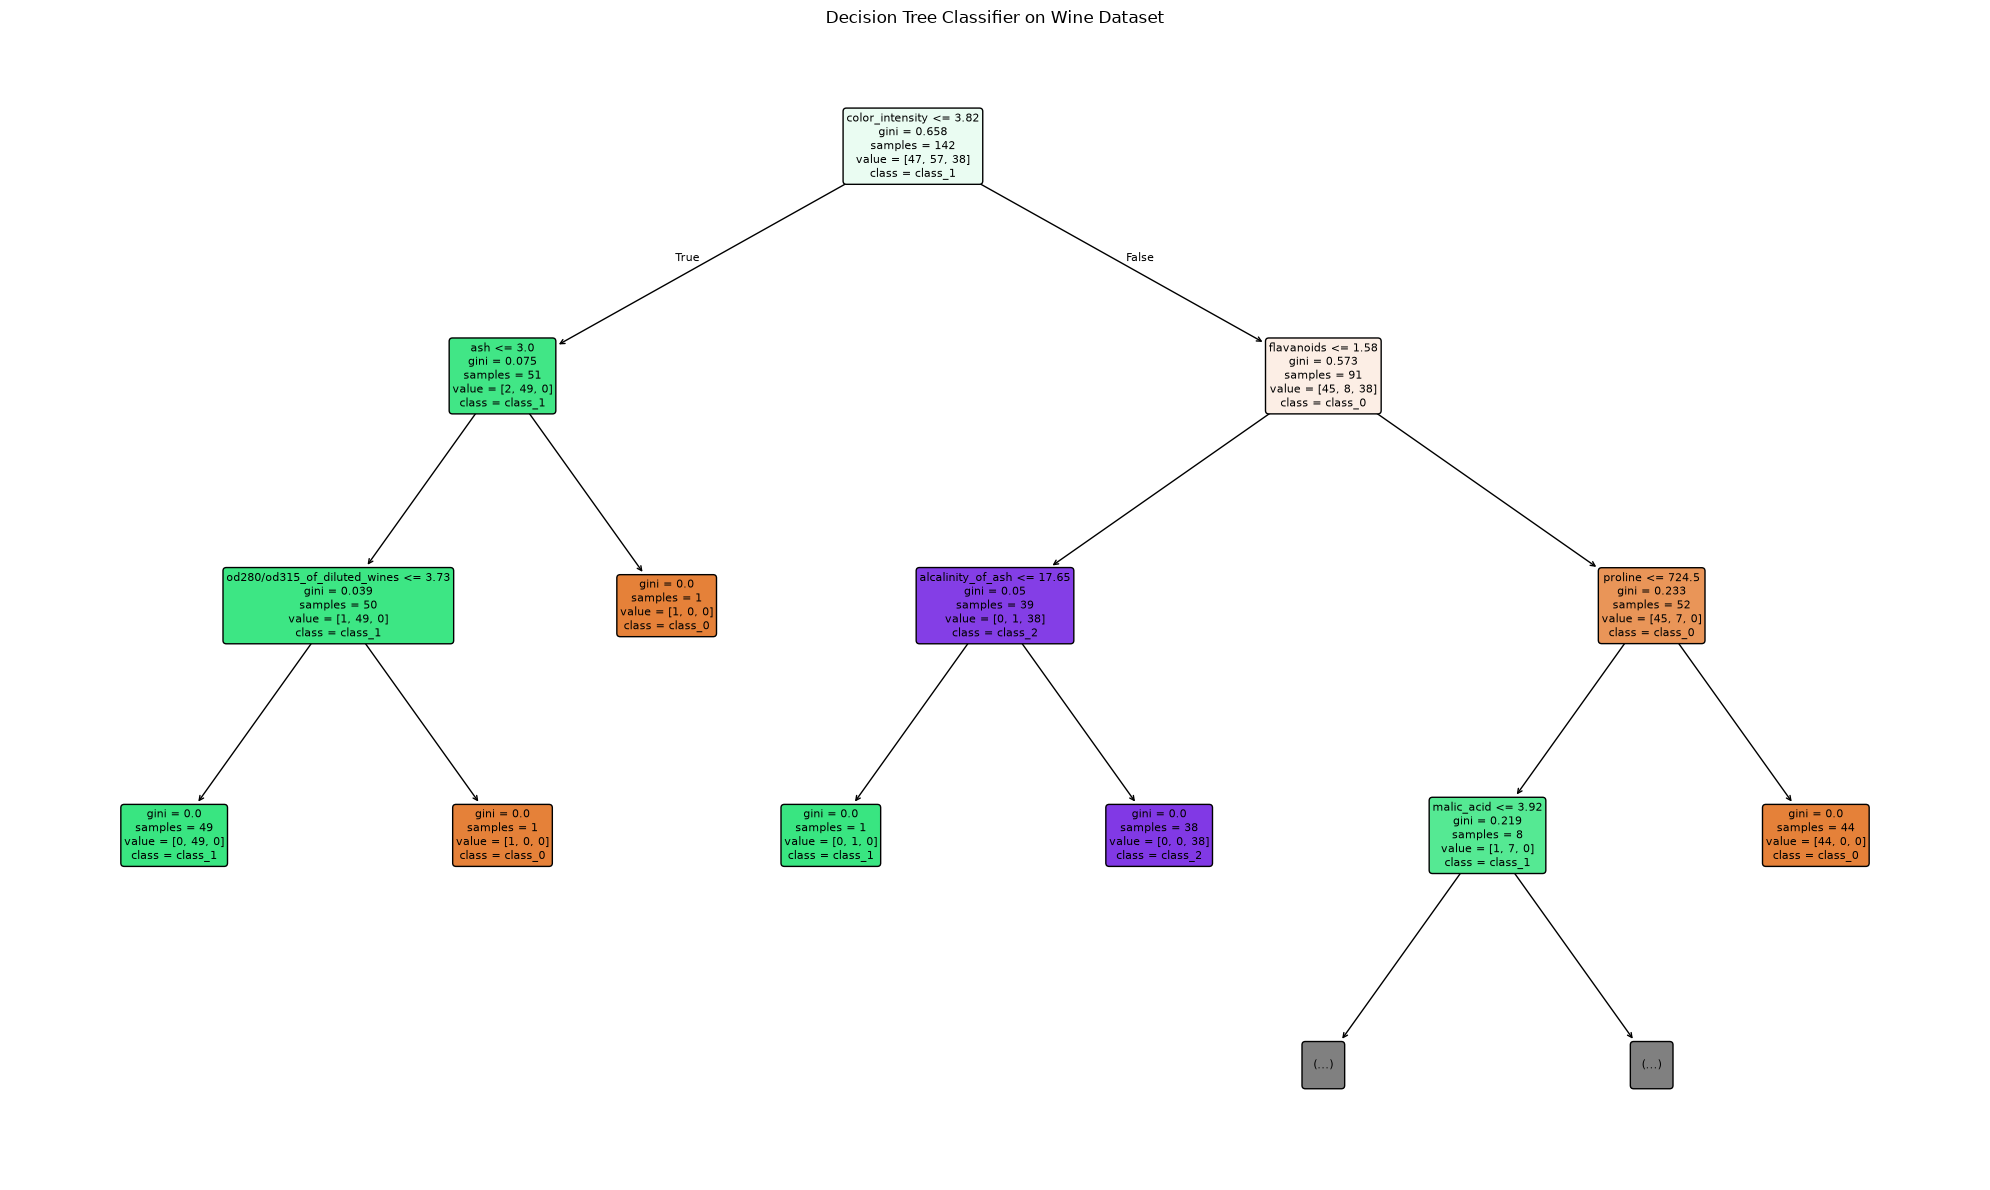

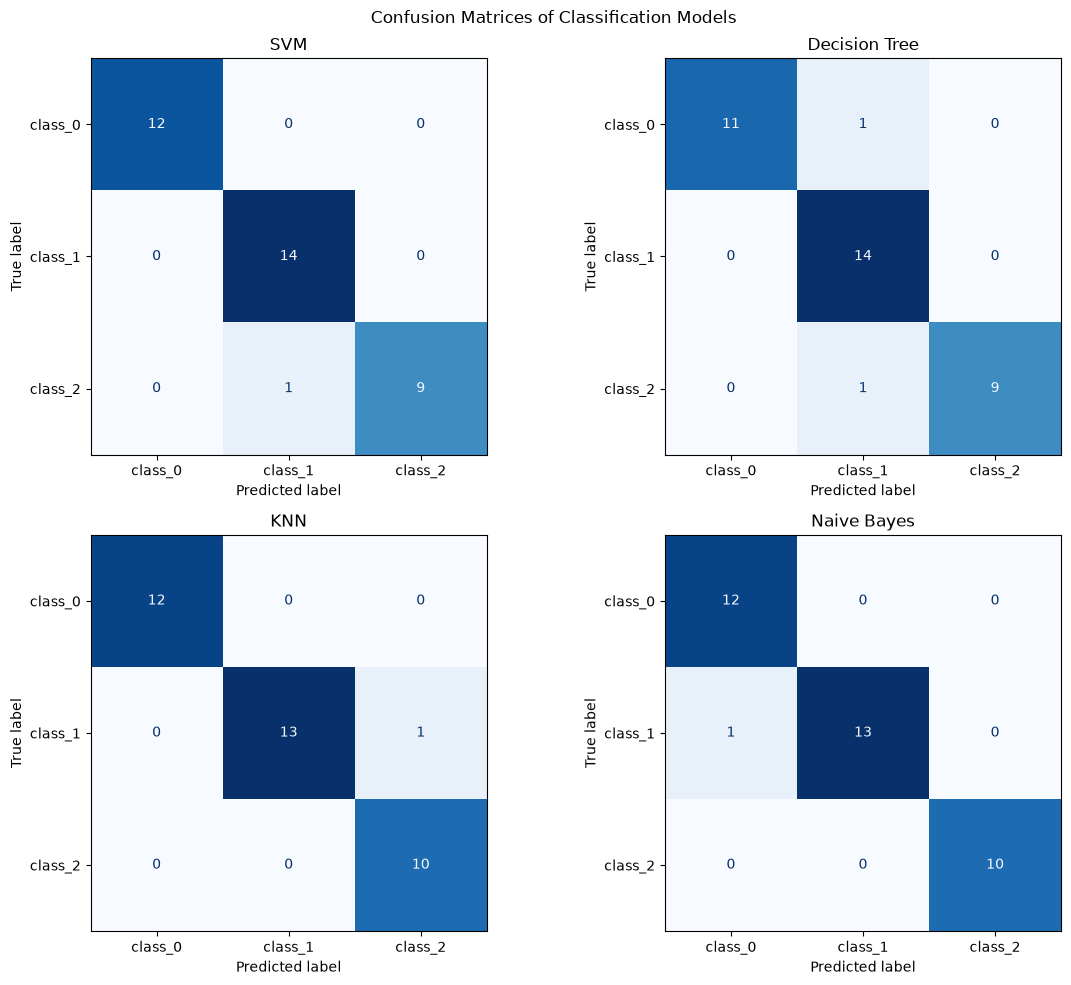

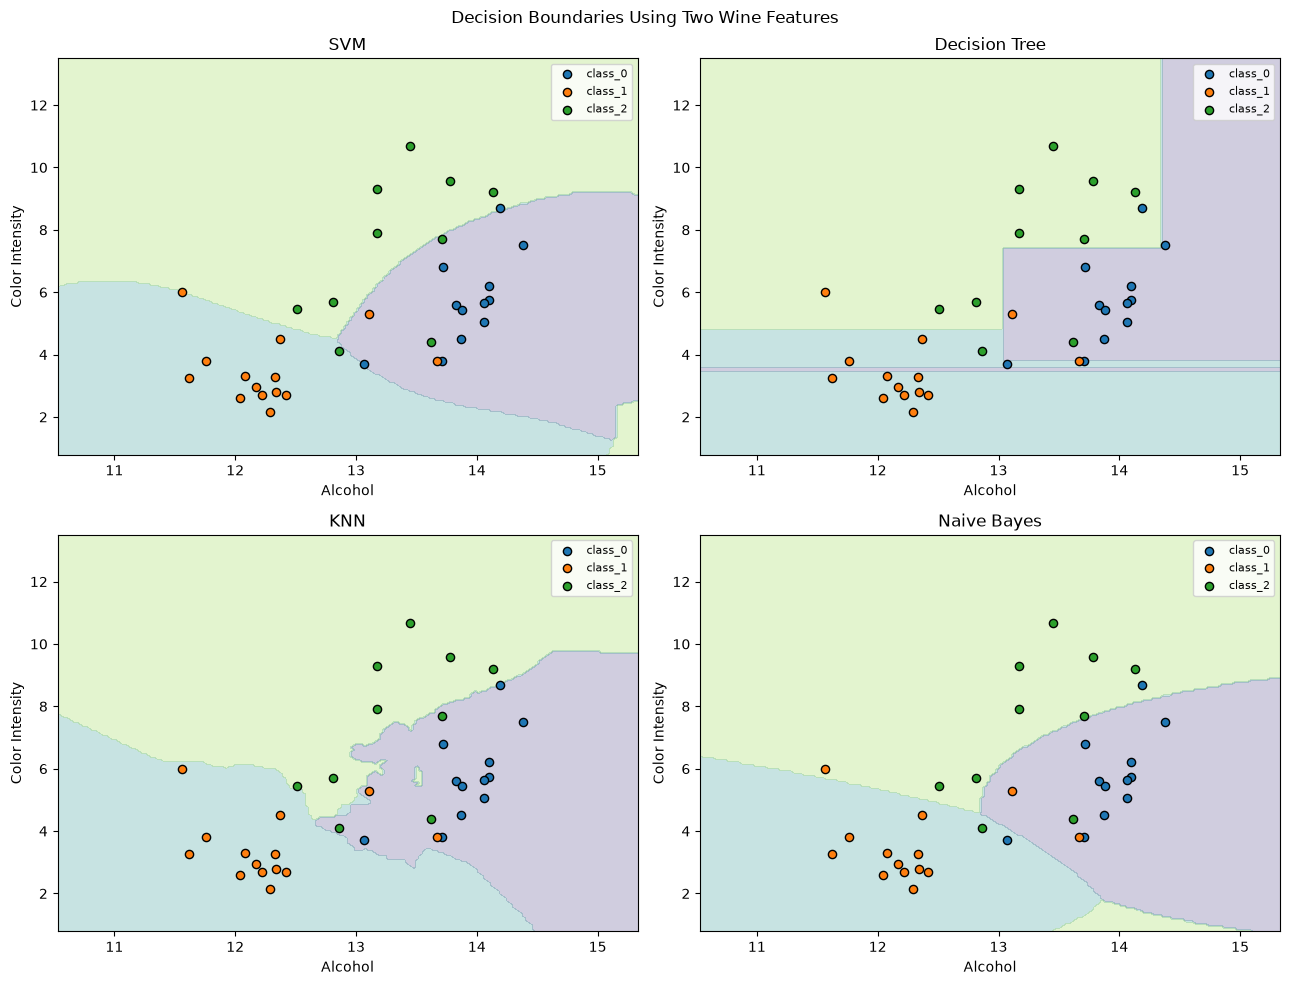


Generated output files:
1. classification_metrics.png
2. classification_log_loss.png
3. decision_tree.png
4. confusion_matrices.png
5. decision_boundaries.png
6. classification_results.csv

Experiment completed successfully.


In [1]:
# ============================================================
# TY B.Tech. AIML - PRACTICAL ASSIGNMENT 04
# PERFORMANCE EVALUATION OF CLASSIFICATION MODELS
# Dataset: Wine Classification Dataset
# Algorithms: SVM, Decision Tree, KNN, Naive Bayes
# ============================================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# A. COMMON SETUP AND EVALUATION HELPER
# ============================================================

# Load the Wine Classification Dataset
wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = pd.Series(wine.target, name="target")

print("=" * 75)
print("PERFORMANCE EVALUATION OF CLASSIFICATION MODELS")
print("Application: Wine Classification")
print("=" * 75)

print("Dataset records:", X.shape[0])
print("Number of input features:", X.shape[1])
print("Number of classes:", len(wine.target_names))
print("Class names:", list(wine.target_names))

print("\nFirst five records:")
print(X.head())

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# ============================================================
# B, C, D, E. DEFINE FOUR CLASSIFICATION MODELS
# ============================================================

models = {

    # B. Support Vector Machine
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ))
    ]),

    # C. Decision Tree
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    # D. K-Nearest Neighbors
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    # E. Gaussian Naive Bayes
    "Naive Bayes": GaussianNB()
}


# ============================================================
# F1. TRAIN AND EVALUATE EACH MODEL
# ============================================================

results = []
predictions = {}
probabilities = {}
execution_times = {}

for name, model in models.items():

    start_time = time.perf_counter()

    # Train the model
    model.fit(X_train, y_train)

    # Predict test class labels
    y_pred = model.predict(X_test)

    # Predict class probabilities for log loss
    y_prob = model.predict_proba(X_test)

    elapsed_time = time.perf_counter() - start_time

    predictions[name] = y_pred
    probabilities[name] = y_prob
    execution_times[name] = elapsed_time

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    )

    loss = log_loss(
        y_test,
        y_prob,
        labels=model.classes_
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "Log loss": loss,
        "Execution time (s)": elapsed_time
    })


# ============================================================
# F2. DISPLAY COMPARATIVE RESULTS
# ============================================================

results_df = pd.DataFrame(results)

print("\n" + "=" * 90)
print("CLASSIFICATION MODEL PERFORMANCE COMPARISON")
print("=" * 90)

print(
    results_df.round(4).to_string(index=False)
)

# Identify the best model according to individual metrics
best_accuracy = results_df.loc[
    results_df["Accuracy"].idxmax()
]

best_f1 = results_df.loc[
    results_df["F1-score"].idxmax()
]

best_loss = results_df.loc[
    results_df["Log loss"].idxmin()
]

print("\nBEST MODEL ANALYSIS")

print(
    "Best Accuracy:",
    best_accuracy["Model"],
    f"({best_accuracy['Accuracy']:.4f})"
)

print(
    "Best F1-score:",
    best_f1["Model"],
    f"({best_f1['F1-score']:.4f})"
)

print(
    "Lowest Log Loss:",
    best_loss["Model"],
    f"({best_loss['Log loss']:.4f})"
)


# ============================================================
# F3. DETAILED CLASSIFICATION REPORTS
# ============================================================

for name, y_pred in predictions.items():

    print("\n" + "=" * 65)
    print("CLASSIFICATION REPORT:", name)
    print("=" * 65)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(wine.target_names)),
            target_names=list(wine.target_names),
            zero_division=0
        )
    )


# ============================================================
# F4. CLASSIFICATION METRICS COMPARISON GRAPH
# ============================================================

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparison of Classification Metrics")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    "classification_metrics.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# F5. LOG LOSS COMPARISON GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Log loss"]
)

plt.title("Log Loss Comparison")
plt.xlabel("Classification Model")
plt.ylabel("Log Loss (lower is better)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "classification_log_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# F6. DECISION TREE VISUALIZATION
# ============================================================

decision_tree = models["Decision Tree"]

plt.figure(figsize=(20, 12))

plot_tree(
    decision_tree,
    feature_names=list(wine.feature_names),
    class_names=list(wine.target_names),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title(
    "Decision Tree Classifier on Wine Dataset"
)

plt.tight_layout()

plt.savefig(
    "decision_tree.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# F7. CONFUSION MATRICES
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10)
)

for ax, (name, y_pred) in zip(
    axes.ravel(),
    predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(wine.target_names))
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=wine.target_names
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle(
    "Confusion Matrices of Classification Models"
)

plt.tight_layout()

plt.savefig(
    "confusion_matrices.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# F8. DECISION-BOUNDARY SCATTER PLOTS
# ============================================================
# For visualization only, these models use two features:
# alcohol and color_intensity.
#
# Main performance metrics above use all 13 features.
# These two-feature models are trained separately and should
# not be confused with the full-feature evaluation models.
# ============================================================

visual_features = [
    "alcohol",
    "color_intensity"
]

X_train_2 = X_train[visual_features]
X_test_2 = X_test[visual_features]

boundary_models = {

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            kernel="rbf",
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]),

    "Naive Bayes": GaussianNB()
}

# Create a grid of feature values
x_min = X[visual_features[0]].min() - 0.5
x_max = X[visual_features[0]].max() + 0.5

y_min = X[visual_features[1]].min() - 0.5
y_max = X[visual_features[1]].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 180),
    np.linspace(y_min, y_max, 180)
)

grid = pd.DataFrame({
    visual_features[0]: xx.ravel(),
    visual_features[1]: yy.ravel()
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for ax, (name, model) in zip(
    axes.ravel(),
    boundary_models.items()
):

    # Fit visualization model using two features
    model.fit(X_train_2, y_train)

    # Predict class for each point on the grid
    grid_predictions = model.predict(grid)

    Z = grid_predictions.reshape(xx.shape)

    ax.contourf(
        xx,
        yy,
        Z,
        alpha=0.25,
        levels=np.arange(
            -0.5,
            len(wine.target_names) + 0.5,
            1
        ),
        cmap="viridis"
    )

    # Show test samples for each class
    for class_id, class_name in enumerate(
        wine.target_names
    ):

        mask = (
            y_test.to_numpy() == class_id
        )

        ax.scatter(
            X_test_2.loc[mask, visual_features[0]],
            X_test_2.loc[mask, visual_features[1]],
            label=class_name,
            edgecolors="black",
            s=35
        )

    ax.set_title(name)

    ax.set_xlabel("Alcohol")

    ax.set_ylabel("Color Intensity")

    ax.legend(fontsize=8)

plt.suptitle(
    "Decision Boundaries Using Two Wine Features"
)

plt.tight_layout()

plt.savefig(
    "decision_boundaries.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# F9. SAVE RESULTS AND DISPLAY FINAL STATUS
# ============================================================

results_df.to_csv(
    "classification_results.csv",
    index=False
)

print("\nGenerated output files:")
print("1. classification_metrics.png")
print("2. classification_log_loss.png")
print("3. decision_tree.png")
print("4. confusion_matrices.png")
print("5. decision_boundaries.png")
print("6. classification_results.csv")

print("\nExperiment completed successfully.")